# Pipeline Gardenia | Etapa 7: Big Data com Apache Spark

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anlbp/Projeto-Gardenia-unifeob/blob/main/recursos/dados/notebook_dados_nao_filtrados/07_spark.ipynb)

Esta é a **versão Colab** da etapa 7. A versão para a VM 3 é o arquivo `pipeline_vm3.py`, que usa o mesmo código de processamento.

## O que muda em relação às etapas anteriores

Nas etapas 3 a 6 o pandas lê **um lote** na memória de uma máquina. Aqui o **Spark** lê **todos os lotes de uma vez** e divide o trabalho em partes que rodam em paralelo (nos núcleos da máquina ou, num cluster, em vários computadores). O código das agregações é o mesmo se os dados crescerem.

**O que o notebook faz**

1. Lê os `trusted_*_N.csv` de todos os lotes e empilha (a chave de cada registro é `lote` + `id`, porque o simulador reinicia os ids a cada ciclo).
2. Monta a tabela de fatos (compra + produto + cliente).
3. Calcula agregações: receita por mês, categoria, faixa etária e top produtos.
4. Faz RFM e agrupa os clientes com o **K-Means do Spark MLlib**.
5. Faz um **teste de escala**: a mesma agregação com 1x, 10x e 100x os dados.
6. Grava resultados em CSV e a tabela de fatos em **Parquet** (formato colunar, padrão em big data).

**Lê:** `trusted_clientes_N.csv`, `trusted_produtos_N.csv`, `trusted_compras_N.csv` (saída do notebook 03).
**Gera:** CSVs de resultado e `fato_vendas.parquet`, por padrão em `{DRIVE_PASTA}/spark`.

> Os lotes são sorteios independentes do simulador. Somar lotes é um consolidado de volume, não a evolução de uma loja real.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuração

In [3]:
# ============================ CONFIGURAÇÃO ============================
FONTE = "drive"             # "drive" | "github" | "upload" | "local"
LOTES = None                # None = todos os lotes encontrados. Ou uma lista, ex.: [1, 2]

DRIVE_PASTA = "/content/drive/MyDrive/gardenia"   # o 03 grava os trusted em {DRIVE_PASTA}/saida
PASTA_TRUSTED = f"{DRIVE_PASTA}/saida"

# --- usado quando FONTE == "github" (os trusted versionados no repositório) ---
GITHUB_USUARIO = "Anlbp"
GITHUB_REPO    = "Projeto-Gardenia-unifeob"
GITHUB_BRANCH  = "main"
PASTA_GITHUB   = "recursos/dados/trusted"
LOTES_GITHUB   = [1]        # quais lotes baixar do GitHub

# --- usado quando FONTE == "local" ---
PASTA_LOCAL = "dados_trusted"

# --- modelo e teste de escala ---
K_FINAL = 3                 # número de segmentos. None = o K de maior silhouette (entre 2 e 7)
FATORES_ESCALA = (1, 10, 100)   # () = não roda o teste de escala

# --- saída ---
SALVAR_NO_DRIVE = True      # True: grava em {DRIVE_PASTA}/spark. False: grava em ./spark_saida
# =======================================================================

## 2. Instalação do Spark e leitura dos dados

In [4]:
# O Spark precisa de Java 17 ou mais novo. No Colab, instala (leva cerca de 1 minuto na primeira vez).
import os, shutil, subprocess, sys

if shutil.which("java") is None or "17" not in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr:
    subprocess.run("apt-get -qq install -y openjdk-17-jre-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]

try:
    import pyspark
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark"], check=True)
    import pyspark
print("pyspark", pyspark.__version__)

pyspark 4.0.4


In [5]:
import urllib.error
import urllib.request

try:
    if FONTE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        PASTA_DADOS = PASTA_TRUSTED

    elif FONTE == "github":
        PASTA_DADOS = "dados_trusted"
        os.makedirs(PASTA_DADOS, exist_ok=True)
        branch = GITHUB_BRANCH.removeprefix("tree/")
        for n in LOTES_GITHUB:
            for t in ["clientes", "produtos", "compras"]:
                nome = f"trusted_{t}_{n}.csv"
                url = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{GITHUB_REPO}/{branch}/{PASTA_GITHUB}/{nome}"
                print("baixando", url)
                urllib.request.urlretrieve(url, os.path.join(PASTA_DADOS, nome))

    elif FONTE == "upload":
        from google.colab import files
        PASTA_DADOS = "dados_trusted"
        os.makedirs(PASTA_DADOS, exist_ok=True)
        print("Selecione os 3 arquivos trusted_*_N.csv de cada lote (gerados pelo notebook 03)")
        for nome, conteudo in files.upload().items():
            with open(os.path.join(PASTA_DADOS, nome), "wb") as f:
                f.write(conteudo)

    elif FONTE == "local":
        PASTA_DADOS = PASTA_LOCAL

    else:
        raise ValueError('FONTE deve ser "drive", "github", "upload" ou "local".')
except urllib.error.HTTPError as e:
    raise FileNotFoundError(f"Não consegui baixar o arquivo ({e.code}). Confira usuário, repositório, pasta e lotes.") from None

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Código do Spark (o mesmo do `pipeline_vm3.py`)

As células abaixo só **definem** as funções. Os resultados aparecem a partir da seção 4.

In [6]:
import glob
import os
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

In [7]:
TABELAS = ["clientes", "produtos", "compras"]
COR_SEGMENTO = {"VIP": "#C44E52", "Regular": "#DD8452", "Baixo engajamento": "#4C72B0"}


def criar_spark(master="local[*]", memoria=None, particoes=8):
    """Sessão Spark. master="local[*]" usa todos os núcleos da máquina; num cluster seria "spark://host:7077"."""
    b = (SparkSession.builder.master(master).appName("gardenia-etapa7")
         .config("spark.ui.enabled", "false")
         .config("spark.sql.shuffle.partitions", str(particoes))
         .config("spark.sql.execution.arrow.pyspark.enabled", "false"))
    if memoria:
        b = b.config("spark.driver.memory", memoria)
    spark = b.getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")
    return spark


def lotes_trusted(pasta):
    """Lotes que podem ser lidos: os 3 trusted_*_N.csv existem e, se a pasta usa marcadores
    (trusted_N.pronto, gravados pela VM 2), o marcador também existe."""
    arquivos = set(os.listdir(pasta)) if os.path.isdir(pasta) else set()
    usa_marcador = any(re.fullmatch(r"trusted_\d+\.pronto", n) for n in arquivos)
    lotes = []
    for n in arquivos:
        m = re.fullmatch(r"trusted_clientes_(\d+)\.csv", n)
        if not m:
            continue
        N = int(m.group(1))
        if not all(f"trusted_{t}_{N}.csv" in arquivos for t in TABELAS):
            continue
        if usa_marcador and f"trusted_{N}.pronto" not in arquivos:
            continue
        lotes.append(N)
    return sorted(lotes)


def ler_tabela(spark, pasta, tabela, lotes):
    """Lê trusted_<tabela>_N.csv de cada lote e empilha, com a coluna 'lote'."""
    partes = []
    for n in lotes:
        caminho = os.path.abspath(os.path.join(pasta, f"trusted_{tabela}_{n}.csv"))
        partes.append(spark.read.csv(caminho, header=True, inferSchema=False).withColumn("lote", F.lit(n)))
    df = partes[0]
    for p in partes[1:]:
        df = df.unionByName(p)
    return df


def carregar(spark, pasta, lotes):
    """Devolve clientes, produtos e compras já tipados. A chave de cada registro é (lote, id),
    porque o simulador reinicia os ids a cada ciclo."""
    cli = (ler_tabela(spark, pasta, "clientes", lotes)
           .select("lote", F.col("id").cast("int").alias("cliente_id"), "nome",
                   F.col("idade").cast("int").alias("idade"),
                   F.to_timestamp("data_cadastro").alias("data_cadastro"),
                   (F.col("cadastro_incompleto") == "True").alias("cadastro_incompleto")))
    cli = cli.withColumn("faixa_etaria", F.when(F.col("idade").isNull(), "sem idade")
                         .when(F.col("idade") < 25, "18-24").when(F.col("idade") < 35, "25-34")
                         .when(F.col("idade") < 45, "35-44").when(F.col("idade") < 55, "45-54")
                         .when(F.col("idade") < 65, "55-64").otherwise("65+"))
    prod = (ler_tabela(spark, pasta, "produtos", lotes)
            .select("lote", F.col("id").cast("int").alias("produto_id"), F.col("nome").alias("produto"),
                    "categoria", F.col("preco").cast("double").alias("preco"),
                    F.col("satisfacao_media").cast("double").alias("satisfacao_media")))
    comp = (ler_tabela(spark, pasta, "compras", lotes)
            .select("lote", F.col("id").cast("int").alias("compra_id"),
                    F.col("cliente_id").cast("int").alias("cliente_id"),
                    F.col("produto_id").cast("int").alias("produto_id"),
                    F.col("quantidade").cast("int").alias("quantidade"),
                    F.col("valor_total").cast("double").alias("valor_total"),
                    F.col("desconto").cast("double").alias("desconto"),
                    F.to_timestamp("data_compra").alias("data_compra"),
                    "status", F.col("satisfacao").cast("int").alias("satisfacao")))
    return cli, prod, comp


def montar_fato(cli, prod, comp):
    """Tabela de fatos: cada compra com os dados do produto e do cliente (join por lote + id)."""
    fato = (comp.join(prod.select("lote", "produto_id", "produto", "categoria", "preco"), ["lote", "produto_id"], "inner")
                .join(cli.select("lote", "cliente_id", "idade", "faixa_etaria"), ["lote", "cliente_id"], "inner")
                .withColumn("valor_liquido", F.col("valor_total") - F.col("desconto"))
                .withColumn("mes", F.date_format("data_compra", "yyyy-MM"))
                .withColumn("valida", F.col("status") != "cancelado"))
    return fato

In [8]:
def pdf(df):
    return df.toPandas()


def analises(cli, prod, fato):
    """Agregações distribuídas: o Spark calcula, e só o resultado pequeno vem para o pandas."""
    v = F.when(F.col("valida"), F.col("valor_liquido")).otherwise(0.0)
    res = {}
    res["resumo_lotes"] = pdf(
        fato.groupBy("lote").agg(
            F.count("*").alias("compras"),
            F.countDistinct("cliente_id").alias("clientes_que_compraram"),
            F.round(F.sum(v), 2).alias("receita_liquida"),
            F.round(F.avg(F.when(~F.col("valida"), 1.0).otherwise(0.0)) * 100, 1).alias("pct_cancelamento"))
        .orderBy("lote"))
    res["receita_mensal"] = pdf(
        fato.groupBy("mes").agg(F.round(F.sum(v), 2).alias("receita_liquida"),
                                F.sum(F.col("valida").cast("int")).alias("compras_validas"))
        .orderBy("mes"))
    res["por_categoria"] = pdf(
        fato.groupBy("categoria").agg(
            F.round(F.sum(v), 2).alias("receita_liquida"),
            F.sum(F.col("valida").cast("int")).alias("compras_validas"),
            F.round(F.avg(F.when(F.col("valida"), F.col("valor_liquido"))), 2).alias("ticket_medio"),
            F.round(F.avg(F.when(~F.col("valida"), 1.0).otherwise(0.0)) * 100, 1).alias("pct_cancelamento"),
            F.round(F.avg("satisfacao"), 2).alias("satisfacao_media"))
        .orderBy(F.desc("receita_liquida")))
    res["por_faixa_etaria"] = pdf(
        fato.groupBy("faixa_etaria").agg(F.round(F.sum(v), 2).alias("receita_liquida"),
                                         F.sum(F.col("valida").cast("int")).alias("compras_validas"))
        .orderBy("faixa_etaria"))
    res["top_produtos"] = pdf(
        fato.groupBy("lote", "produto_id", "produto", "categoria").agg(F.round(F.sum(v), 2).alias("receita_liquida"))
        .orderBy(F.desc("receita_liquida")).limit(10))
    return res

In [9]:
def rfm_spark(cli, fato):
    """RFM por cliente (lote, cliente_id). Data de referência = última data_cadastro do lote.
    Compras canceladas não contam."""
    ref = cli.groupBy("lote").agg(F.max("data_cadastro").alias("data_ref"))
    base = fato.filter("valida").join(ref, "lote")
    return (base.groupBy("lote", "cliente_id").agg(
        F.greatest(F.lit(0), F.datediff(F.first("data_ref"), F.max("data_compra"))).alias("recencia"),
        F.countDistinct("compra_id").alias("frequencia"),
        F.round(F.sum("valor_liquido"), 2).alias("monetario")))


def preparar_features(rfm):
    d = (rfm.withColumn("f_rec", F.log1p("recencia")).withColumn("f_freq", F.log1p("frequencia"))
            .withColumn("f_val", F.log1p("monetario")))
    vec = VectorAssembler(inputCols=["f_rec", "f_freq", "f_val"], outputCol="bruto").transform(d)
    modelo_esc = StandardScaler(inputCol="bruto", outputCol="features", withMean=True, withStd=True).fit(vec)
    return modelo_esc.transform(vec)


def avaliar_k(X, ks=range(2, 8), semente=42):
    linhas = []
    ev = ClusteringEvaluator(featuresCol="features", predictionCol="prediction", metricName="silhouette")
    for k in ks:
        m = KMeans(k=k, seed=semente, featuresCol="features", predictionCol="prediction").fit(X)
        linhas.append({"k": k, "inercia": round(m.summary.trainingCost, 2),
                       "silhouette": round(ev.evaluate(m.transform(X)), 3)})
    return pd.DataFrame(linhas)


def segmentar(X, k, semente=42):
    """K-Means do MLlib. Os grupos recebem nome pela nota do centro:
    recência baixa + frequência alta + valor alto = nota maior. Maior nota = VIP."""
    modelo = KMeans(k=k, seed=semente, featuresCol="features", predictionCol="cluster").fit(X)
    centros = np.array(modelo.clusterCenters())                       # colunas: rec, freq, val (padronizadas)
    nota = -centros[:, 0] + centros[:, 1] + centros[:, 2]
    ordem = list(np.argsort(nota))                                    # menor nota primeiro
    if k == 2:
        nomes = ["Baixo engajamento", "VIP"]
    elif k == 3:
        nomes = ["Baixo engajamento", "Regular", "VIP"]
    else:
        nomes = ["Baixo engajamento"] + [f"Regular {i}" for i in range(1, k - 1)] + ["VIP"]
    mapa = {int(c): nomes[i] for i, c in enumerate(ordem)}
    pred = modelo.transform(X)
    seg = F.create_map(*[x for c, n in mapa.items() for x in (F.lit(c), F.lit(n))])[F.col("cluster")]
    pred = pred.withColumn("segmento", seg)
    sil = ClusteringEvaluator(featuresCol="features", predictionCol="cluster", metricName="silhouette").evaluate(pred)
    return pred.select("lote", "cliente_id", "recencia", "frequencia", "monetario", "cluster", "segmento"), sil, nomes[::-1]


def perfil_segmentos(seg, ordem):
    total_v = seg.agg(F.sum("monetario")).first()[0]
    total_c = seg.count()
    p = pdf(seg.groupBy("segmento").agg(
        F.count("*").alias("clientes"),
        F.round(F.avg("recencia"), 1).alias("recencia_media"),
        F.round(F.avg("frequencia"), 2).alias("frequencia_media"),
        F.round(F.avg("monetario"), 2).alias("valor_medio"),
        F.round(F.sum("monetario"), 2).alias("valor_total")))
    p["pct_clientes"] = (p["clientes"] / total_c * 100).round(1)
    p["pct_valor"] = (p["valor_total"] / total_v * 100).round(1)
    p["segmento"] = pd.Categorical(p["segmento"], categories=ordem, ordered=True)
    return p.sort_values("segmento").reset_index(drop=True)

In [10]:
def teste_de_escala(fato, fatores=(1, 10, 100)):
    """Repete a tabela de fatos N vezes (crossJoin) e mede o tempo de uma agregação.
    Serve para mostrar o comportamento do Spark com volume maior; os dados repetidos não vão para os resultados."""
    spark = fato.sparkSession
    linhas = []
    for f in fatores:
        grande = fato.crossJoin(spark.range(f).withColumnRenamed("id", "copia"))
        t0 = time.time()
        n = grande.count()
        grande.groupBy("categoria", "mes").agg(F.sum("valor_liquido").alias("r")).collect()
        linhas.append({"fator": f, "linhas": n, "segundos": round(time.time() - t0, 2)})
    return pd.DataFrame(linhas)

In [11]:
def salvar_resultados(pasta, res, avaliacao, perf, seg, fato, escala=None):
    """CSV para os resultados pequenos; Parquet (particionado por lote) para a tabela de fatos."""
    os.makedirs(pasta, exist_ok=True)
    tabelas = dict(res)
    tabelas["avaliacao_k"] = avaliacao
    tabelas["perfil_segmentos"] = perf
    tabelas["rfm_segmentos"] = seg.toPandas()
    if escala is not None:
        tabelas["teste_de_escala"] = escala
    for nome, d in tabelas.items():
        destino = os.path.join(pasta, f"{nome}.csv")
        d.to_csv(destino + ".tmp", index=False)
        os.replace(destino + ".tmp", destino)
        print(f"  {destino}  ({len(d)} linhas)")
    parquet = os.path.abspath(os.path.join(pasta, "fato_vendas.parquet"))
    fato.drop("valida").write.mode("overwrite").partitionBy("lote").parquet(parquet)
    print(f"  {parquet}  (Parquet, particionado por lote)")

In [12]:
def grafico_resumo(res, perf, avaliacao, ordem):
    """Painel 2x3 com os resultados principais."""
    fig, ax = plt.subplots(2, 3, figsize=(17, 9))
    cor = "#4C72B0"

    m = res["receita_mensal"]
    ax[0, 0].plot(m["mes"], m["receita_liquida"] / 1e3, marker="o", color=cor)
    ax[0, 0].set_title("Receita líquida por mês (1º e último mês podem estar incompletos)")
    ax[0, 0].set_ylabel("R$ mil"); ax[0, 0].tick_params(axis="x", rotation=60)

    c = res["por_categoria"]
    ax[0, 1].barh(c["categoria"][::-1], c["receita_liquida"][::-1] / 1e3, color=cor)
    ax[0, 1].set_title("Receita líquida por categoria"); ax[0, 1].set_xlabel("R$ mil")

    ax[0, 2].barh(c["categoria"][::-1], c["pct_cancelamento"][::-1], color="#C44E52")
    ax[0, 2].set_title("% de compras canceladas por categoria"); ax[0, 2].set_xlabel("%")

    f = res["por_faixa_etaria"]
    ax[1, 0].bar(f["faixa_etaria"], f["receita_liquida"] / 1e3, color=cor)
    ax[1, 0].set_title("Receita líquida por faixa etária"); ax[1, 0].set_ylabel("R$ mil")

    cores = [COR_SEGMENTO.get(s, "#888888") for s in perf["segmento"].astype(str)]
    ax[1, 1].bar(perf["segmento"].astype(str), perf["clientes"], color=cores)
    for i, (n, pv) in enumerate(zip(perf["clientes"], perf["pct_valor"])):
        ax[1, 1].text(i, n, f"{pv:.0f}% do valor", ha="center", va="bottom", fontsize=9)
    ax[1, 1].set_title("Clientes por segmento (K-Means no Spark)"); ax[1, 1].set_ylabel("clientes")

    ax[1, 2].plot(avaliacao["k"], avaliacao["silhouette"], marker="o", color=cor)
    ax[1, 2].set_title("Silhouette por número de grupos (K)"); ax[1, 2].set_xlabel("K"); ax[1, 2].set_ylabel("silhouette")
    for a in ax.ravel():
        a.grid(alpha=.3)
    fig.tight_layout()
    return fig

## 4. Carga e tabela de fatos

In [13]:
spark = criar_spark("local[*]")
print("Spark", spark.version, "| paralelismo:", spark.sparkContext.defaultParallelism)

lotes = lotes_trusted(PASTA_DADOS)
if LOTES is not None:
    lotes = [n for n in lotes if n in LOTES]
if not lotes:
    raise FileNotFoundError(
        f"Não encontrei lotes completos em {PASTA_DADOS}.\n"
        "Rode antes o notebook 03 (ele grava trusted_clientes/produtos/compras_N.csv) e confira FONTE e as pastas na configuração."
    )
print("Lotes lidos:", lotes)

cli, prod, comp = carregar(spark, PASTA_DADOS, lotes)
fato = montar_fato(cli, prod, comp).cache()
print(f"clientes: {cli.count()} | produtos: {prod.count()} | compras: {comp.count()} | fato_vendas: {fato.count()}")
fato.limit(5).toPandas()

Spark 4.0.4 | paralelismo: 2
Lotes lidos: [1]
clientes: 5000 | produtos: 2305 | compras: 1184 | fato_vendas: 1184


,lote,cliente_id,produto_id,compra_id,quantidade,valor_total,desconto,data_compra,status,satisfacao,produto,categoria,preco,idade,faixa_etaria,valor_liquido,mes,valida
0,1,753,1,3625,9,4494.95,945.11,2026-09-02 17:31:44.583642,pendente,NaN,Sofá Plus,Livros,589.74,43,35-44,3549.84,2026-09,True
1,1,1234,4,3878,3,3681.66,576.32,2025-11-03 17:31:44.583642,pendente,2.0,Ursinho Premium,Casa,97.11,18,18-24,3105.34,2025-11,True
2,1,1481,14,2706,3,3653.78,201.86,2026-07-04 17:31:44.583642,cancelado,NaN,Sofá Pro,Livros,527.95,28,25-34,3451.92,2026-07,False
3,1,3123,15,4069,4,626.32,152.49,2026-03-20 17:31:44.583642,cancelado,NaN,Ursinho Max,Alimentos,180.47,71,65+,473.83,2026-03,False
4,1,2312,17,4408,3,2753.51,478.90,2025-11-09 17:31:44.583642,enviado,3.0,Feijão Basic,Esportes,455.77,75,65+,2274.61,2025-11,True


## 5. Agregações distribuídas

O Spark faz os `groupBy` sobre todos os lotes e só o resultado pequeno vem para o pandas, para exibir e desenhar.

In [14]:
res = analises(cli, prod, fato)
for nome in ["resumo_lotes", "por_categoria", "por_faixa_etaria", "top_produtos"]:
    print("\n---", nome)
    display(res[nome])


--- resumo_lotes


,lote,compras,clientes_que_compraram,receita_liquida,pct_cancelamento
0,1,1184,1063,1948058.3,20.8



--- por_categoria


,categoria,receita_liquida,compras_validas,ticket_medio,pct_cancelamento,satisfacao_media
0,Esportes,324018.25,154,2104.01,17.6,3.02
1,Roupas,311430.64,152,2048.89,22.8,3.01
2,Livros,304085.78,148,2054.63,19.1,3.10
3,Alimentos,266249.86,127,2096.46,18.1,3.20
4,Casa,261623.94,121,2162.18,23.4,3.11
5,Eletrônicos,244264.64,117,2087.73,20.9,2.98
6,Brinquedos,236385.19,119,1986.43,23.7,2.88



--- por_faixa_etaria


,faixa_etaria,receita_liquida,compras_validas
0,18-24,202655.41,102
1,25-34,307931.09,145
2,35-44,249311.49,136
3,45-54,338949.31,157
4,55-64,361899.74,170
5,65+,487311.26,228



--- top_produtos


,lote,produto_id,produto,categoria,receita_liquida
0,1,3781,Ursinho Plus,Livros,9253.88
1,1,548,Sofá Plus,Esportes,9013.05
2,1,764,Romance Max,Roupas,9006.32
3,1,4468,Smartphone Pro,Brinquedos,8851.72
4,1,1968,Ursinho Plus,Livros,8522.37
5,1,614,Notebook Max,Brinquedos,8521.55
6,1,752,Camiseta Premium,Alimentos,8396.06
7,1,549,Notebook Premium,Roupas,8316.06
8,1,2076,Notebook Plus,Alimentos,8090.77
9,1,2510,Sofá Pro,Eletrônicos,8011.57


## 6. RFM e K-Means no Spark MLlib

Mesma lógica do notebook 06 (log1p, padronização, nota para nomear os grupos), agora sobre todos os lotes. Cada cliente é identificado por `lote` + `cliente_id`.

In [15]:
X = preparar_features(rfm_spark(cli, fato)).cache()
print("Clientes com compra válida:", X.count())

avaliacao = avaliar_k(X)
display(avaliacao)

k = K_FINAL or int(avaliacao.loc[avaliacao["silhouette"].idxmax(), "k"])
seg, sil, ordem = segmentar(X, k)
seg = seg.cache()
perf = perfil_segmentos(seg, ordem)
print(f"K usado: {k} | silhouette do modelo final: {sil:.3f}")
display(perf)

Clientes com compra válida: 868


,k,inercia,silhouette
0,2,1674.88,0.805
1,3,1162.31,0.584
2,4,715.54,0.667
3,5,594.16,0.602
4,6,480.32,0.597
5,7,490.25,0.564


K usado: 3 | silhouette do modelo final: 0.584


,segmento,clientes,recencia_media,frequencia_media,valor_medio,valor_total,pct_clientes,pct_valor
0,VIP,68,124.8,2.03,4444.50,302226.04,7.8,15.5
1,Regular,570,206.1,1.00,2530.62,1442451.97,65.7,74.0
2,Baixo engajamento,230,119.5,1.00,884.26,203380.29,26.5,10.4


## 7. Teste de escala

In [16]:
if FATORES_ESCALA:
    escala = teste_de_escala(fato, FATORES_ESCALA)
    display(escala)
else:
    escala = None
    print("Teste de escala desligado (FATORES_ESCALA vazio).")

,fator,linhas,segundos
0,1,1184,1.03
1,10,11840,0.60
2,100,118400,0.59


## 8. Gráficos

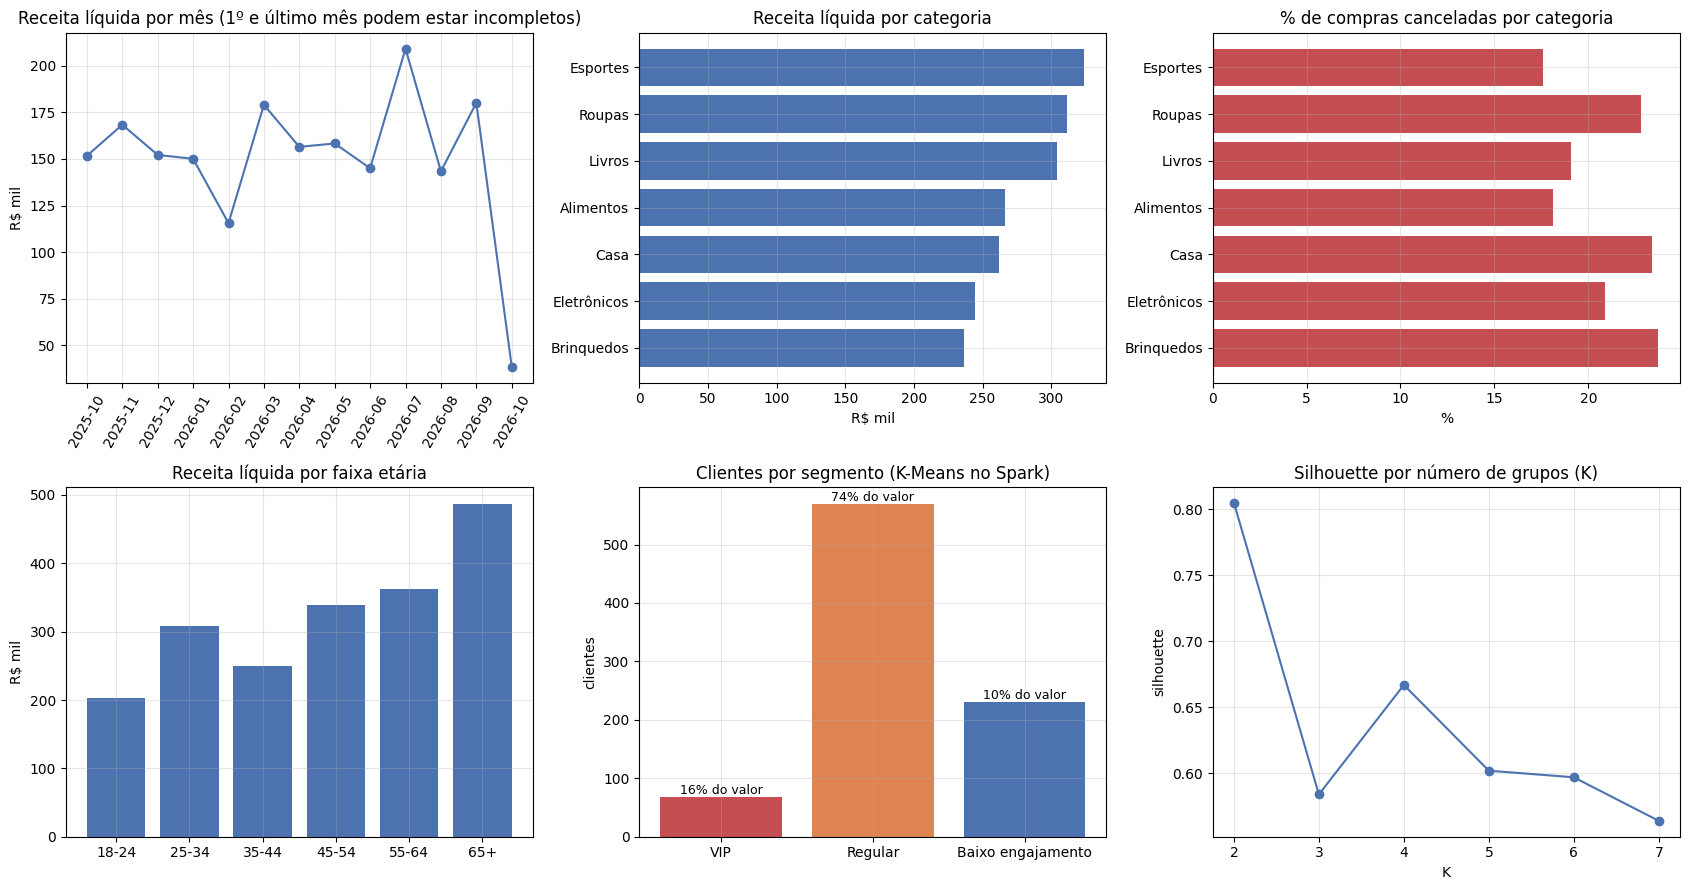

In [17]:
fig = grafico_resumo(res, perf, avaliacao, ordem)
plt.show()

## 9. Salvar resultados

In [18]:
SAIDA = f"{DRIVE_PASTA}/spark" if (SALVAR_NO_DRIVE and FONTE == "drive") else "spark_saida"
salvar_resultados(SAIDA, res, avaliacao, perf, seg, fato, escala)
fig.savefig(os.path.join(SAIDA, "spark_resumo.png"), dpi=110, bbox_inches="tight")
spark.stop()

  /content/drive/MyDrive/gardenia/spark/resumo_lotes.csv  (1 linhas)
  /content/drive/MyDrive/gardenia/spark/receita_mensal.csv  (13 linhas)
  /content/drive/MyDrive/gardenia/spark/por_categoria.csv  (7 linhas)
  /content/drive/MyDrive/gardenia/spark/por_faixa_etaria.csv  (6 linhas)
  /content/drive/MyDrive/gardenia/spark/top_produtos.csv  (10 linhas)
  /content/drive/MyDrive/gardenia/spark/avaliacao_k.csv  (6 linhas)
  /content/drive/MyDrive/gardenia/spark/perfil_segmentos.csv  (3 linhas)
  /content/drive/MyDrive/gardenia/spark/rfm_segmentos.csv  (868 linhas)
  /content/drive/MyDrive/gardenia/spark/teste_de_escala.csv  (3 linhas)
  /content/drive/MyDrive/gardenia/spark/fato_vendas.parquet  (Parquet, particionado por lote)


## 11. Decisões de arquitetura: por que não usamos Sqoop nem YARN

**Sqoop**
- O Sqoop transfere dados entre um banco relacional (MySQL, Postgres etc.) e o Hadoop (HDFS/Hive).
- No nosso fluxo, a fonte é o simulador da VM 1, que gera **arquivos CSV**, não um banco. Não há tabela relacional para importar.
- A transferência entre as VMs é feita por `scp`/SSH, com um arquivo marcador (`.pronto`) gravado por último e cópia atômica, para ninguém ler um arquivo pela metade.
- Se a fonte fosse um banco relacional, o Spark lê direto por JDBC (`spark.read.jdbc`). O Apache Sqoop foi desativado pela Apache.

**YARN**
- O YARN é o gerenciador de recursos de um cluster Hadoop: divide CPU e memória entre jobs em vários computadores.
- Rodamos o Spark em **modo local** (`local[*]`), numa única máquina, usando todos os núcleos dela. Sem cluster, não há recursos a distribuir, e o volume dos dados (alguns milhares de linhas por lote) não justifica um.
- O código não muda para rodar no YARN: basta trocar o *master* para `yarn` e ter o Hadoop configurado na VM 3.

**Controle de execução**
- Sem um gerenciador de jobs, a repetição é feita pelo modo `vigiar` do `pipeline_vm3.py`, e o arquivo `ultimo_processamento.json` evita reprocessar lotes que não mudaram.
- É uma solução simples, **não equivalente** a YARN ou Airflow: não há filas, prioridades nem recuperação automática de falhas.

**Limitação**
- Neste volume, o teste de escala mostrou tempo parecido com 1x, 10x e 100x os dados, porque o custo fixo do Spark domina. O benefício do YARN e de um cluster só aparece com dados muito maiores.

## 10. Interpretação

Preencha depois de rodar, com os números que apareceram:

- **Volume:** quantos lotes, clientes e compras o Spark leu de uma vez.
- **Receita:** em quais categorias e faixas etárias ela se concentra, e o que isso sugere.
- **Segmentos:** quantos clientes e quanto do valor total cada um tem; qual ação cabe a cada grupo.
- **Escala:** como o tempo variou com 1x, 10x e 100x os dados. Em dados pequenos o custo fixo do Spark domina, e o ganho aparece com volume maior.

Checklist antes do commit:

- [ ] o notebook 03 foi rodado para os lotes que serão lidos;
- [ ] a versão da VM 3 (`pipeline_vm3.py`) gera os mesmos números com os mesmos dados;
- [ ] as frases de interpretação foram preenchidas.